# 02. Workflow run: rule-level results and accuracy against ground truth

**Business question:** if every record goes through an automated workflow (standardise, validate, correct,
de-duplicate, flag), how many can be released without a person, and how often is the automatic decision right?

Workflow (`src/workflow.py`):
1. **Standardise** (`src/standardize.py`): upper-case, USPS-style suffixes and directionals, unit split out of line 1,
   PO box format, state names to codes, ZIP+4 split, lost leading zeros restored.
2. **Validate** against the ZIP reference: missing fields, unknown ZIP, city or state disagreeing with the ZIP,
   missing house number.
3. **Correct**: fill city/state from the ZIP, correct the state when the city agrees with the ZIP, fuzzy-match
   typo'd cities with `difflib` (ratio of 0.8 or more and a clear winner), fill the ZIP from city + state when the
   city has a single ZIP.
4. **De-duplicate**: same standardised address and identical name = exact duplicate (merged into the earliest
   record); same address and name similarity of 0.85 or more = possible duplicate.
5. **Flag** each record VERIFIED, AUTO_CORRECTED, NEEDS_REVIEW or INVALID with the reasons.

In [1]:
import sys
sys.path.append('../src')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_colwidth', 60)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
FIG = '../reports/figures'
from reference import load_zip_reference
raw = pd.read_csv('../data/raw/address_records.csv', dtype=str, keep_default_na=False)
ref = load_zip_reference('../data/raw/zip_reference.csv')
import time
from workflow import run_workflow
gt = pd.read_csv('../data/raw/address_ground_truth.csv', dtype=str, keep_default_na=False)

In [2]:
t0 = time.time()
res = run_workflow(raw, ref)
print(f'processed {len(res):,} records in {time.time() - t0:.1f}s')
res[['record_id', 'final_line1', 'final_line2', 'final_city', 'final_state', 'final_zip', 'status', 'reasons']].head(8)

processed 49,920 records in 5.4s


,record_id,final_line1,final_line2,final_city,final_state,final_zip,status,reasons
0,R044543,962 HILL CIR,UNIT 21A,LINWOOD,MT,53787,VERIFIED,
1,R003643,8482 SYCAMORE PL,,FAIRDALE,NY,15238,VERIFIED,
2,R015246,4214 LAUREL BLVD,,FOX FALLS,TX,76173,VERIFIED,
3,R021404,3207 SPRUCE CIR,,LAKEFORD,WI,54987,AUTO_CORRECTED,PUNCTUATION_REMOVED
4,R048385,PO BOX 4833,,CARLWICK,SC,25980,AUTO_CORRECTED,DUPLICATE_MERGED|PO_BOX
5,R040771,4794 CHERRY RD,,RIVERMONT,KS,67492,VERIFIED,
6,R015472,1596 HARBOR ST,,HAWRIDGE,CA,93635,VERIFIED,
7,R039003,3659 PROSPECT RD,,SILVER GROVE,AK,97232,VERIFIED,


## 1. Status distribution

In [3]:
order = ['VERIFIED', 'AUTO_CORRECTED', 'NEEDS_REVIEW', 'INVALID']
status = res.status.value_counts().reindex(order).to_frame('records')
status['share'] = (status.records / len(res)).round(4)
status

,records,share
status,,
VERIFIED,33038,0.6618
AUTO_CORRECTED,13291,0.2662
NEEDS_REVIEW,3043,0.0610
INVALID,548,0.0110


## 2. Rule-level results
How often each validation rule fired and each correction was applied.

In [4]:
rules = res.rules_fired.explode().dropna().value_counts().rename('records fired')
corr = res.corrections.explode().dropna().value_counts().rename('records corrected')
issues = res.issues.explode().dropna().value_counts().rename('records flagged')
pd.concat([rules, corr, issues], axis=1).fillna(0).astype(int).sort_values(['records fired', 'records corrected'], ascending=False)

,records fired,records corrected,records flagged
CITY_ZIP_MISMATCH,3280,0,0
MISSING_ZIP,1448,0,0
DUPLICATE,1440,0,0
PO_BOX,1430,0,0
MISSING_CITY,933,0,0
MISSING_STATE,909,0,0
ZIP_NOT_FOUND,631,0,0
POSSIBLE_DUPLICATE,496,0,496
ZIP_STATE_MISMATCH,493,0,0
MISSING_LINE1,308,0,308


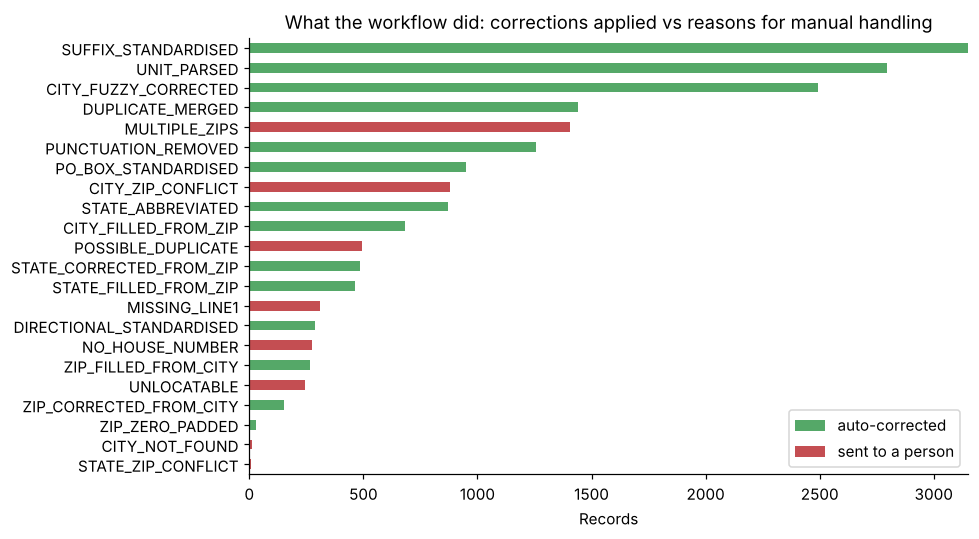

In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
c = corr.sort_values()
i = issues.sort_values()
both = pd.concat([c.rename('auto-corrected'), i.rename('sent to a person')], axis=1).fillna(0)
both = both.loc[both.sum(axis=1).sort_values().index]
both.plot.barh(ax=ax, stacked=True, color=['#55A868', '#C44E52'])
ax.set_title('What the workflow did: corrections applied vs reasons for manual handling')
ax.set_xlabel('Records'); ax.set_ylabel('')
plt.tight_layout(); plt.savefig(f'{FIG}/rule_level_results.png', bbox_inches='tight'); plt.show()

## 3. Accuracy against the planted ground truth
The ground truth records, for every record, the status the review policy expects and the true clean address.

In [6]:
m = res.merge(gt, on='record_id')
acc = (m.status == m.expected_status).mean()
print(f'status accuracy: {acc:.4f} on {len(m):,} records')
cm = pd.crosstab(m.expected_status, m.status).reindex(index=order, columns=order, fill_value=0)
cm

status accuracy: 0.9952 on 49,920 records


status,VERIFIED,AUTO_CORRECTED,NEEDS_REVIEW,INVALID
expected_status,,,,
VERIFIED,33037,0,13,0
AUTO_CORRECTED,0,13069,2,0
NEEDS_REVIEW,1,222,3028,0
INVALID,0,0,0,548


In [7]:
from sklearn.metrics import classification_report
print(classification_report(m.expected_status, m.status, labels=order, digits=3))

                precision    recall  f1-score   support

      VERIFIED      1.000     1.000     1.000     33050
AUTO_CORRECTED      0.983     1.000     0.992     13071
  NEEDS_REVIEW      0.995     0.931     0.962      3251
       INVALID      1.000     1.000     1.000       548

      accuracy                          0.995     49920
     macro avg      0.995     0.983     0.988     49920
  weighted avg      0.995     0.995     0.995     49920



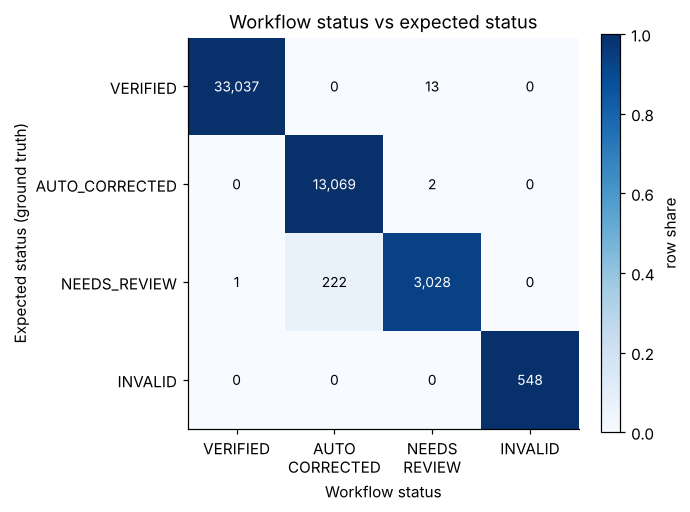

In [8]:
fig, ax = plt.subplots(figsize=(6, 5))
norm = cm.div(cm.sum(axis=1), axis=0)
im = ax.imshow(norm, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(4), [o.replace('_', '\n') for o in order]); ax.set_yticks(range(4), order)
for r in range(4):
    for c in range(4):
        ax.text(c, r, f'{cm.iat[r, c]:,}', ha='center', va='center', color='white' if norm.iat[r, c] > .5 else 'black', fontsize=9)
ax.set_xlabel('Workflow status'); ax.set_ylabel('Expected status (ground truth)')
ax.set_title('Workflow status vs expected status')
plt.colorbar(im, ax=ax, fraction=.046, label='row share')
plt.tight_layout(); plt.savefig(f'{FIG}/status_confusion.png', bbox_inches='tight'); plt.show()

### Are the released records correct?
For records the workflow releases without a person (VERIFIED or AUTO_CORRECTED), compare every final field with the
true clean address. A wrong auto-correction is worse than a review, so this is the number that matters.

In [9]:
released = m[m.status.isin(['VERIFIED', 'AUTO_CORRECTED'])]
fields = [('final_line1', 'true_line1'), ('final_line2', 'true_line2'), ('final_city', 'true_city'),
          ('final_state', 'true_state'), ('final_zip', 'true_zip')]
field_acc = pd.Series({a.replace('final_', ''): (released[a] == released[b]).mean() for a, b in fields})
all_ok = np.logical_and.reduce([released[a] == released[b] for a, b in fields])
print(f'released records: {len(released):,}; all five fields correct: {all_ok.mean():.5f} ({(~all_ok).sum()} records with an error)')
field_acc.to_frame('field accuracy').T.round(5)

released records: 46,329; all five fields correct: 0.99998 (1 records with an error)


,line1,line2,city,state,zip
field accuracy,1.0,1.0,1.0,1.0,0.99998


In [10]:
dups = m[m.duplicate_of_y != '']
print(f'planted duplicates: {len(dups):,}; flagged as exact duplicate of the right master: '
      f'{(dups.duplicate_of_x == dups.duplicate_of_y).sum():,}; as possible duplicate of the right master: '
      f'{(dups.possible_duplicate_of == dups.duplicate_of_y).sum():,}')
print(f'non-duplicates wrongly flagged as possible duplicates: {((m.duplicate_of_y == "") & (m.possible_duplicate_of != "")).sum()}')

planted duplicates: 1,920; flagged as exact duplicate of the right master: 1,440; as possible duplicate of the right master: 480
non-duplicates wrongly flagged as possible duplicates: 16


### Accuracy by planted issue

In [11]:
ex = m.assign(issue=m.planted_issues.str.split('|')).explode('issue')
ex['issue'] = ex.issue.replace('', '(clean)')
by_issue = ex.groupby('issue').apply(lambda g: pd.Series({
    'records': len(g), 'expected': g.expected_status.mode()[0],
    'status accuracy': (g.status == g.expected_status).mean(),
    'auto-corrected': (g.status == 'AUTO_CORRECTED').mean(), 'needs review': (g.status == 'NEEDS_REVIEW').mean()}))
by_issue.sort_values('status accuracy').round(3)

,records,expected,status accuracy,auto-corrected,needs review
issue,,,,,
city_typo_major,522,NEEDS_REVIEW,0.588,0.412,0.577
unit_in_line1,2805,AUTO_CORRECTED,0.993,0.935,0.056
missing_zip,1204,NEEDS_REVIEW,0.995,0.218,0.773
state_spelled_out,869,AUTO_CORRECTED,0.995,0.930,0.062
suffix_variant,4618,AUTO_CORRECTED,0.995,0.940,0.051
zip_transposed,704,NEEDS_REVIEW,0.996,0.216,0.778
missing_state,473,AUTO_CORRECTED,0.996,0.970,0.025
po_box,1421,AUTO_CORRECTED,0.996,0.668,0.052
wrong_city,499,NEEDS_REVIEW,0.998,0.002,0.990


### Where the workflow disagrees with the policy
The largest disagreement is heavy city typos (three or more edits) that the policy sends to review but the fuzzy
matcher still resolves. Check whether those auto-corrections were right.

In [12]:
dis = m[m.status != m.expected_status]
print(dis.groupby(['expected_status', 'status']).size().rename('records').to_string())
over = dis[(dis.expected_status == 'NEEDS_REVIEW') & (dis.status == 'AUTO_CORRECTED')]
ok = np.logical_and.reduce([over[a] == over[b] for a, b in fields])
print(f'\nexpected NEEDS_REVIEW but auto-corrected: {len(over)}; of these, final address fully correct: {ok.sum()} ({ok.mean():.1%})')

expected_status  status        
AUTO_CORRECTED   NEEDS_REVIEW        2
NEEDS_REVIEW     AUTO_CORRECTED    222
                 VERIFIED            1
VERIFIED         NEEDS_REVIEW       13



expected NEEDS_REVIEW but auto-corrected: 222; of these, final address fully correct: 222 (100.0%)


In [13]:
out = res[['record_id', 'status', 'reasons', 'final_line1', 'final_line2', 'final_city', 'final_state', 'final_zip',
           'duplicate_of', 'possible_duplicate_of', 'suggestion']]
out.to_csv('../data/processed/workflow_results.csv', index=False)
status.to_csv('../data/processed/status_summary.csv')
print(f'saved {len(out):,} rows')

saved 49,920 rows


## Findings

* The workflow processed **49,920 records in about 5 seconds**: **66.2% VERIFIED**, **26.6% AUTO_CORRECTED**,
  **6.1% NEEDS_REVIEW** and **1.1% INVALID**.
* The most frequent automatic fixes were suffix standardisation (3,150), unit parsing (2,794), fuzzy city
  correction (2,493), exact-duplicate merges (1,440) and punctuation removal (1,255). The main reasons for manual
  handling were several possible ZIPs for a city (1,405), city/ZIP conflicts (878) and possible duplicates (496).
* Status accuracy against the planted ground truth is **99.52%**. NEEDS_REVIEW recall is 0.931 and AUTO_CORRECTED
  precision 0.983: the main disagreement is 222 heavy city typos (three or more edits) that the policy sends to
  review but the fuzzy matcher resolved, and **all 222 were corrected to the right address**.
* Of the **46,329 records released without a person**, all five address fields are correct for 99.998% (1 record
  has a wrong ZIP).
* Duplicates: all 1,440 exact re-submissions were merged into the right master and all 480 near-duplicates (a typo
  in the name) were flagged for review against the right master; 16 non-duplicates (household members with similar
  names) were flagged as possible duplicates.
* Results are saved to `data/processed/workflow_results.csv` for notebooks 03 and 04.